In [1]:
import duckdb
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

RAW_GLOB = '../data/raw/**/*.parquet'
EMB_COLS = [f'A{i:02d}' for i in range(64)]
SEED = 42
np.random.seed(SEED)

In [2]:
cols = duckdb.query(f"SELECT * FROM read_parquet('{RAW_GLOB}') LIMIT 1").df().columns.tolist()
print("Total columns:", len(cols))
print("Non-embedding:", [c for c in cols if not (c.startswith('A') and len(c)==3)][:20])
print("Embedding-like:", [c for c in cols if c.startswith('A')][:5])

Total columns: 71
Non-embedding: ['lat', 'lon', 'label', 'label_name', 'homogeneity', 'h3_cell', 'sample_cell']
Embedding-like: ['A00', 'A01', 'A02', 'A03', 'A04']


In [3]:
def load_sample(n_per_class=10000, per_country_cap=None, dedupe_children=True,
                exclude_countries=('DE',), seed=SEED):
    excl = "','".join(c.upper() for c in exclude_countries)
    emb_sel = ", ".join(EMB_COLS)

    # dedupe children to one row per h3_cell, but do it per-class with a LIMIT
    # so DuckDB never sorts the whole 45M-row set at once.
    dedup_cte = """
        , deduped AS (
            SELECT * FROM (
                SELECT *,
                       row_number() OVER (PARTITION BY h3_cell ORDER BY random()) AS _rn
                FROM base
            ) WHERE _rn = 1
        )
    """ if dedupe_children else ", deduped AS (SELECT * FROM base)"

    con = duckdb.connect()
    con.execute("SET preserve_insertion_order=false")
    con.execute("SET memory_limit='10GB'")

    q = f"""
        WITH base AS (
            SELECT {emb_sel}, label_name, h3_cell, lat, lon,
                   regexp_extract(filename, 'raw/[^/]+/([^/]+)/', 1) AS country
            FROM read_parquet('{RAW_GLOB}', filename=true)
            WHERE upper(regexp_extract(filename, 'raw/[^/]+/([^/]+)/', 1)) NOT IN ('{excl}')
        )
        {dedup_cte}
        , ranked AS (
            SELECT *, row_number() OVER (PARTITION BY label_name ORDER BY random()) AS _cls_rn
            FROM deduped
        )
        SELECT * EXCLUDE (_cls_rn{', _rn' if dedupe_children else ''})
        FROM ranked
        WHERE _cls_rn <= {n_per_class}
    """
    df = con.execute(q).df()
    con.close()
    return df.reset_index(drop=True)

In [4]:
sample = load_sample(10000)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [5]:
X = sample[EMB_COLS].to_numpy(dtype='float64')   # was .values
y = sample['label_name'].to_numpy()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {X_tr.shape}, Test (unfiltered): {X_te.shape}")

Train: (88000, 64), Test (unfiltered): (22000, 64)


In [6]:
def remove_overlap(X, y, k=10, agree_threshold=0.5, return_mask=False):
    Xs = StandardScaler().fit_transform(X)
    nn = NearestNeighbors(n_neighbors=k+1).fit(Xs)
    _, idx = nn.kneighbors(Xs)
    idx = idx[:, 1:]
    same = (y[idx] == y[:, None]).mean(axis=1)
    keep = same >= agree_threshold
    print(f"k={k}, threshold={agree_threshold}: keep {keep.sum()}/{len(y)} "
          f"({100*keep.mean():.1f}%), removed {(~keep).sum()}")
    removed = pd.Series(y[~keep]).value_counts()
    if len(removed):
        print("Removed per class:\n" + removed.to_string())
    return keep if return_mask else (X[keep], y[keep])

K, AGREE = 10, 0.5
X_tr_filt, y_tr_filt = remove_overlap(X_tr, y_tr, k=K, agree_threshold=AGREE)

k=10, threshold=0.5: keep 79773/88000 (90.7%), removed 8227
Removed per class:
Grassland                 2633
Bare/sparse vegetation    1272
Tree cover                1130
Cropland                   750
Snow and ice               575
Permanent water bodies     520
Shrubland                  412
Herbaceous wetland         374
Moss and lichen            366
Built-up                   141
Mangroves                   54


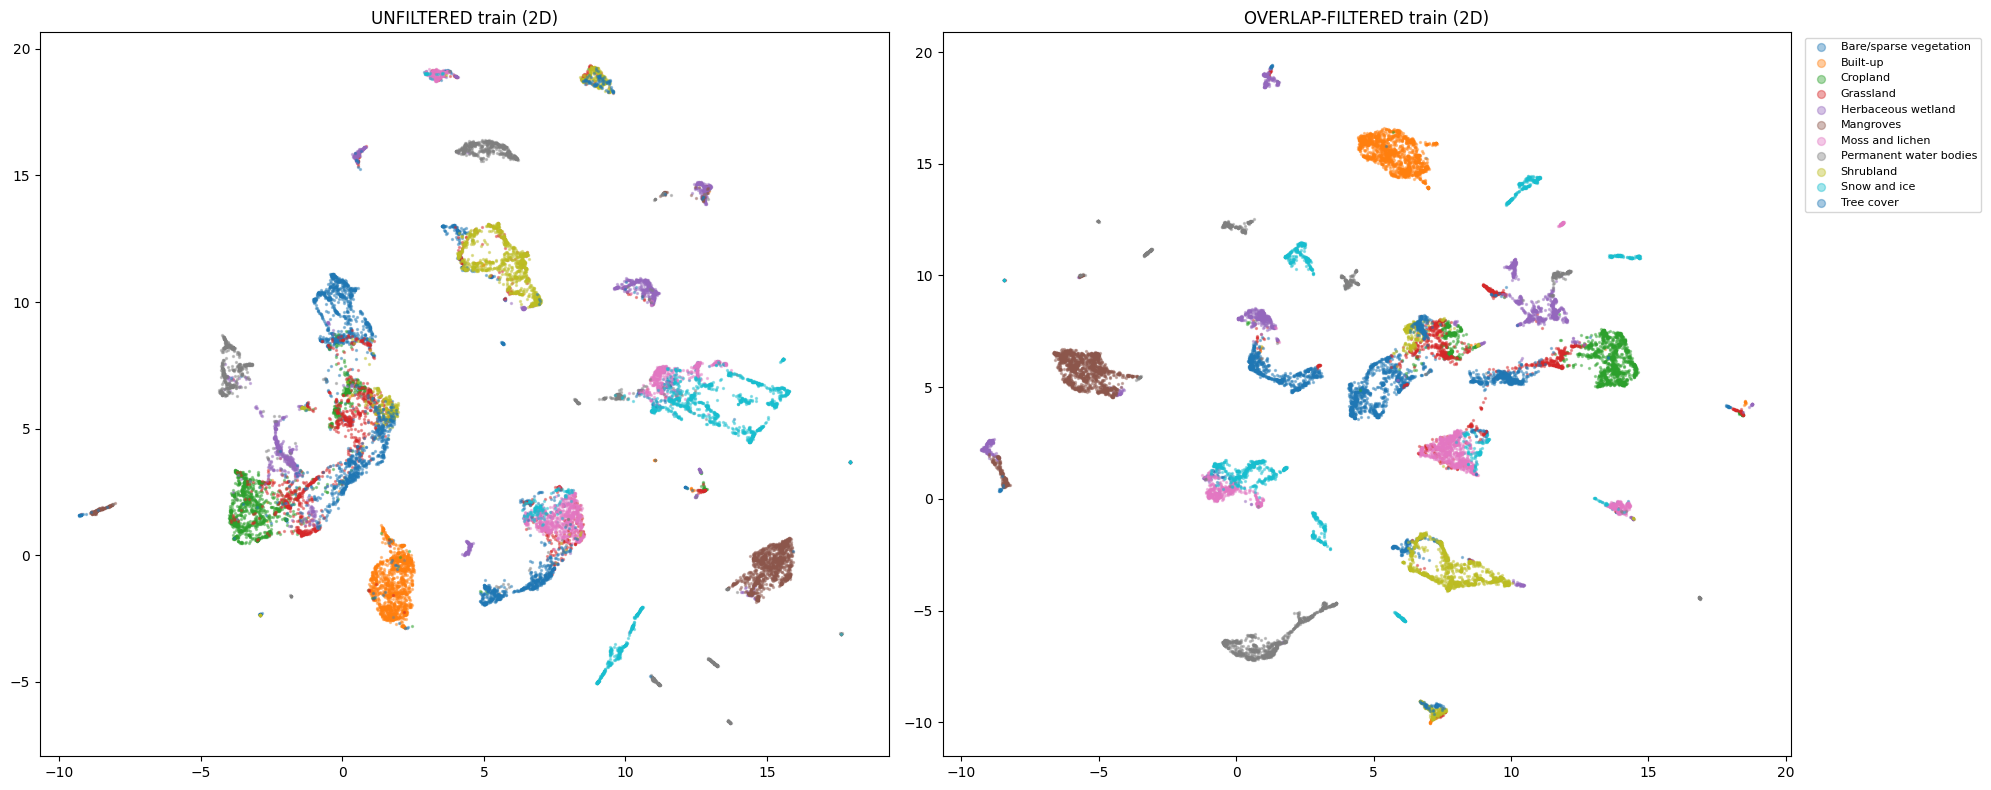

In [7]:
import umap

def make_umap(X, n_components, seed=SEED):
    return umap.UMAP(n_components=n_components, random_state=seed,
                     init='random', n_neighbors=15, min_dist=0.1
                    ).fit_transform(StandardScaler().fit_transform(X))

def sub(X, y, n=15000, seed=SEED):
    if len(y) <= n: return X, y
    i = np.random.RandomState(seed).choice(len(y), n, replace=False)
    return X[i], y[i]

Xu_full, yu_full = sub(X_tr, y_tr)
Xu_filt, yu_filt = sub(X_tr_filt, y_tr_filt)
emb2_full, emb2_filt = make_umap(Xu_full, 2), make_umap(Xu_filt, 2)

def scatter2d(ax, emb, y, title):
    for cls in np.unique(y):
        m = y == cls
        ax.scatter(emb[m,0], emb[m,1], s=2, alpha=0.4, label=cls)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
scatter2d(axes[0], emb2_full, yu_full, 'UNFILTERED train (2D)')
scatter2d(axes[1], emb2_filt, yu_filt, 'OVERLAP-FILTERED train (2D)')
axes[1].legend(markerscale=4, bbox_to_anchor=(1.01,1), loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

# TODO: explore outlier detecion methods

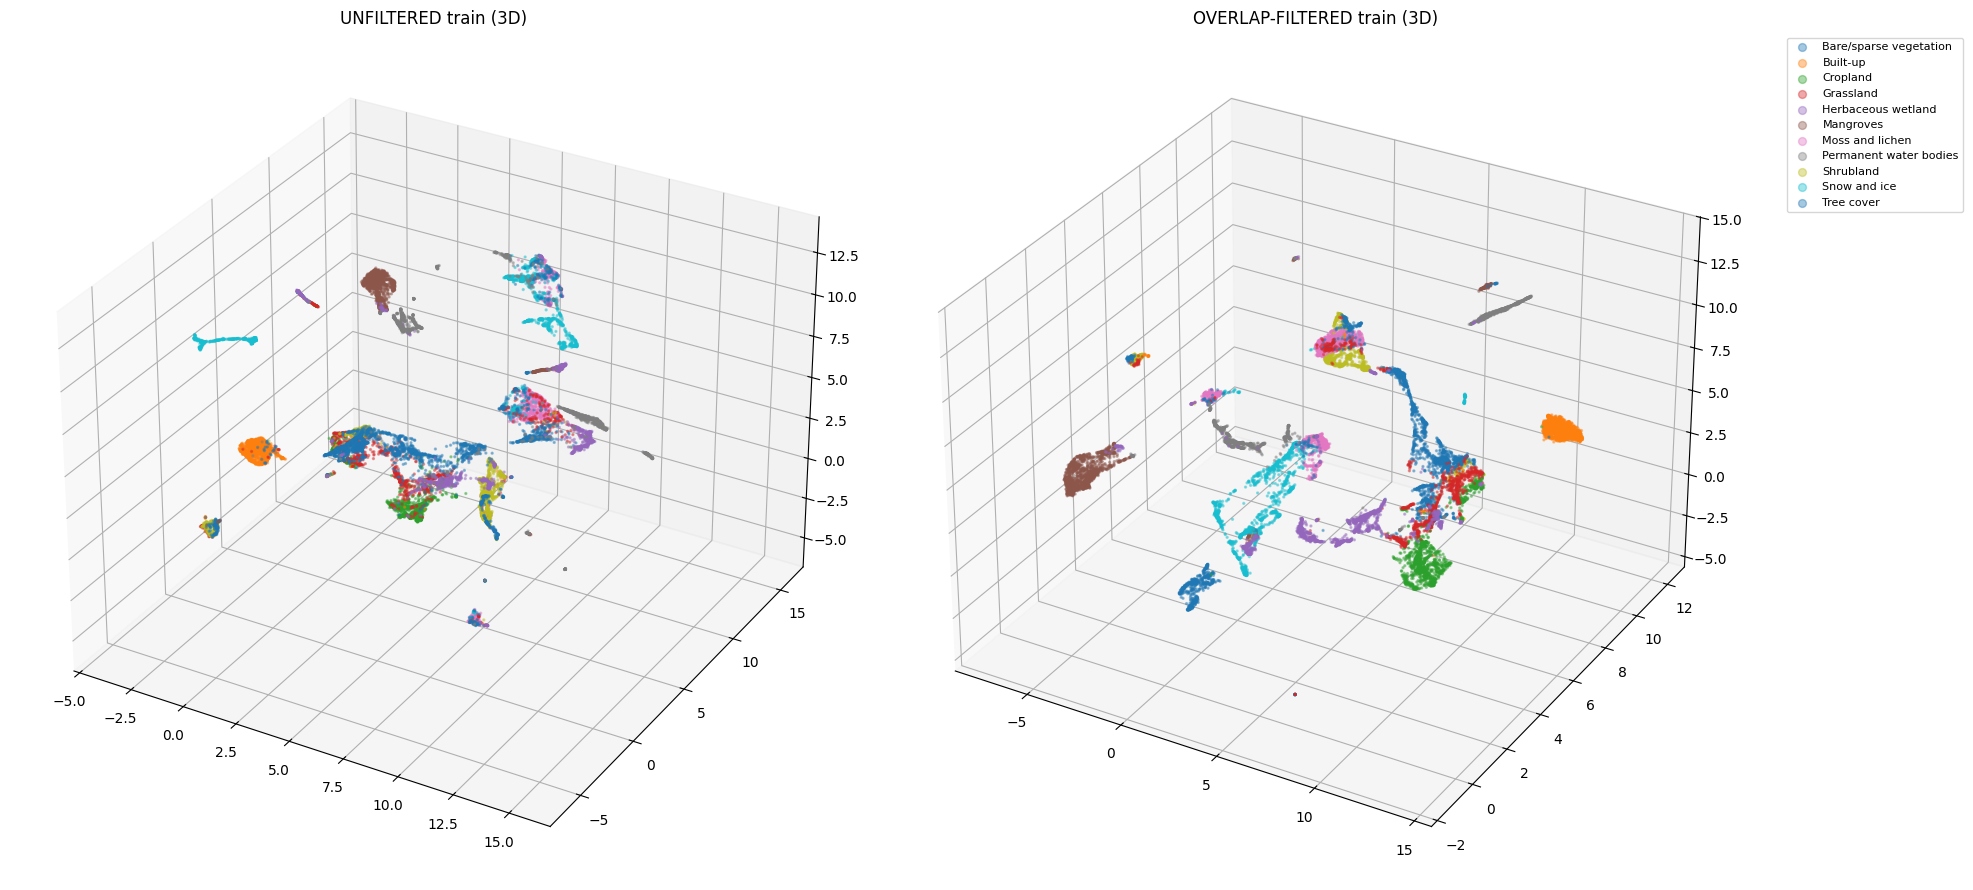

In [8]:
from mpl_toolkits.mplot3d import Axes3D  # noqa
emb3_full, emb3_filt = make_umap(Xu_full, 3), make_umap(Xu_filt, 3)

def scatter3d(ax, emb, y, title):
    for cls in np.unique(y):
        m = y == cls
        ax.scatter(emb[m,0], emb[m,1], emb[m,2], s=2, alpha=0.4, label=cls)
    ax.set_title(title)

fig = plt.figure(figsize=(20, 9))
ax1 = fig.add_subplot(121, projection='3d')
ax2 = fig.add_subplot(122, projection='3d')
scatter3d(ax1, emb3_full, yu_full, 'UNFILTERED train (3D)')
scatter3d(ax2, emb3_filt, yu_filt, 'OVERLAP-FILTERED train (3D)')
ax2.legend(markerscale=4, bbox_to_anchor=(1.05,1), loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

In [9]:
import plotly.express as px

def plotly3d(emb, y, title):
    d = pd.DataFrame({'x': emb[:,0], 'y': emb[:,1], 'z': emb[:,2], 'class': y})
    fig = px.scatter_3d(d, x='x', y='y', z='z', color='class', title=title, opacity=0.5)
    fig.update_traces(marker=dict(size=2)); fig.update_layout(height=700)
    return fig

plotly3d(emb3_filt, yu_filt, 'Overlap-filtered train (interactive 3D)').show()